# SPAM / HAM SMS Classification — Improved Pipeline

This notebook documents the **improved** version of the project. Heavy model training lives in `train.py`
(so results are reproducible with one command); this notebook explains the choices and shows the evidence.
Run `python train.py` first so `models/` and `outputs/` exist.

**What changed vs. the original version**

| # | Problem in original | Fix |
|---|---|---|
| 1 | Best model picked on the *test set* (optimistic) | Model selection by repeated stratified **grouped cross-validation on train only**; test set used once |
| 2 | Exact and near-duplicate messages could leak into test | **De-duplication + near-duplicate grouping** before splitting |
| 3 | Cleaning deleted digits, punctuation, case, `£`, `!`; HTML leftovers (`&lt;#&gt;`) | Model reads the **raw, HTML-unescaped text** + **character n-grams** |
| 4 | Selected on F1 while README says precision matters | **Calibrated probabilities + tuned threshold** for a target spam precision |
| 5 | Forced hard decision on borderline messages | Explicit **REVIEW band** for uncertain messages |
| 6 | No uncertainty on results | **Bootstrap 95% CIs** on test metrics |
| 7 | Easy to dodge with `fr33` / `w.i.n` | **Obfuscation augmentation** (train only) + measured robustness |
| 8 | Black box; hard-coded `D:\` path | **Explanations**, relative paths, `Pipeline`s, tests, CI, Streamlit + FastAPI |

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from src.data import SEED, load_data
from src.features import HandcraftedFeatures

pd.set_option("display.max_colwidth", 120, "display.width", 180)
OUT = ROOT / "outputs"

## 1. Load & explore (with de-duplication)

Raw messages: 5572 | exact duplicates removed: 414 | remaining: 5158 | near-duplicate groups: 5000
label
ham     4516
spam     642


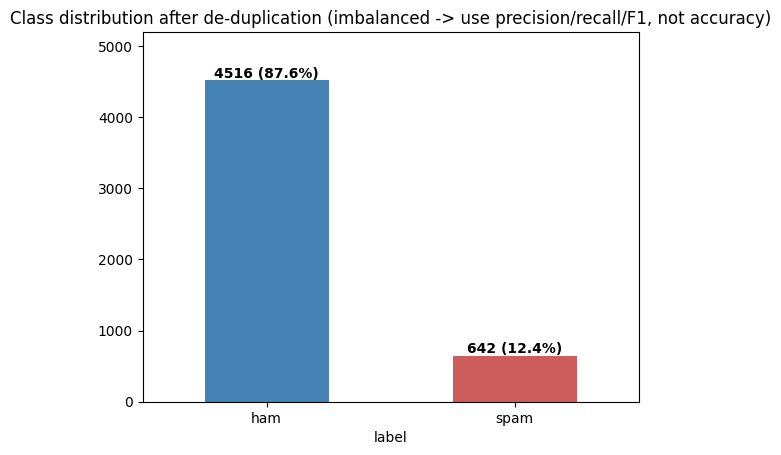

In [2]:
raw = load_data(deduplicate=False)
df = load_data(deduplicate=True)
print(f"Raw messages: {len(raw)} | exact duplicates removed: {len(raw)-len(df)} | remaining: {len(df)} | near-duplicate groups: {df.group.nunique()}")
print(df.label.value_counts().to_string())
ax = df.label.value_counts().plot(kind="bar", color=["steelblue","indianred"], rot=0)
for i,(c,p) in enumerate(zip(df.label.value_counts(), df.label.value_counts(normalize=True)*100)):
    ax.text(i, c+40, f"{c} ({p:.1f}%)", ha="center", fontweight="bold")
plt.title("Class distribution after de-duplication (imbalanced -> use precision/recall/F1, not accuracy)")
plt.ylim(0, df.label.value_counts().max()*1.15); plt.show()

## 2. Why the raw text is better than heavily cleaned text

The original cleaning removed digits, punctuation, capitalisation and currency symbols. But these are exactly
what spam messages are full of (phone numbers, short codes, `£`, `!!!`, SHOUTING). Compare simple statistics:

In [3]:
feats = HandcraftedFeatures()._raw(df.message)
names = ["log_length","log_words","digit_ratio","upper_ratio","log_exclaims","has_url","has_currency","has_long_number"]
stats = pd.DataFrame(feats, columns=names).assign(label=df.label.values).groupby("label").mean().T
stats["spam / ham"] = (stats["spam"] / stats["ham"]).round(2)
stats.round(3)

label,ham,spam,spam / ham
log_length,4.039,4.893,1.21
log_words,2.525,3.164,1.25
digit_ratio,0.004,0.115,26.35
upper_ratio,0.057,0.110,1.91
log_exclaims,0.102,0.407,3.99
has_url,0.000,0.137,619.02
has_currency,0.006,0.338,56.53
has_long_number,0.001,0.765,1151.28


Spam has a far higher share of digits, uppercase letters, currency symbols and long numbers.
A pipeline that deletes those characters throws away signal. Character n-grams on the raw text keep it, and also cope
with obfuscation like `fr33` / `w1n`.

## 3. Method
1. **Split**: ~80/20 stratified **group** split (near-duplicate templates never straddle train/test); test set is never used for choices.
2. **Select** among 5 feature sets x 3 models with 5-fold x 2-repeat stratified group CV on the training set.
   `baseline_clean` reproduces the original approach (cleaned text, 3000 features).
3. **Tune** `C` with `GridSearchCV` (train only).
4. **Augment** training spam with obfuscated copies (`fr33`, `w.i.n`, `pr ize`) — training data only.
5. **Calibrate** (sigmoid) so scores are real probabilities; pick the decision threshold on *out-of-fold* predictions:
   the highest recall that still keeps spam precision >= 0.98.
6. **Review band**: the ~5% most uncertain messages just below the threshold go to human review.
7. **Evaluate once** on the held-out test set with bootstrap confidence intervals and an obfuscation stress test.

## 4. Cross-validated model comparison (training set only)

In [4]:
cv = pd.read_csv(OUT/"cv_results.csv")
cv.round(4)

,features,model,precision,recall,f1,f1_std
0,char,LinearSVM,0.9969,0.9348,0.9645,0.0187
1,word+char,LinearSVM,0.9927,0.9358,0.9631,0.0195
2,char,LogisticRegression,0.9878,0.9387,0.9624,0.0168
3,word+char,LogisticRegression,0.9780,0.9426,0.9597,0.0159
4,word+char+hand,LinearSVM,0.9895,0.9154,0.9507,0.0176
5,word+char+hand,LogisticRegression,0.9773,0.9125,0.9434,0.0189
6,word,LinearSVM,0.9544,0.9163,0.9346,0.0259
7,word,LogisticRegression,0.9163,0.9290,0.9222,0.0213
8,baseline_clean,LinearSVM,0.9198,0.8433,0.8794,0.0204
9,baseline_clean,LogisticRegression,0.8775,0.8570,0.8668,0.0303


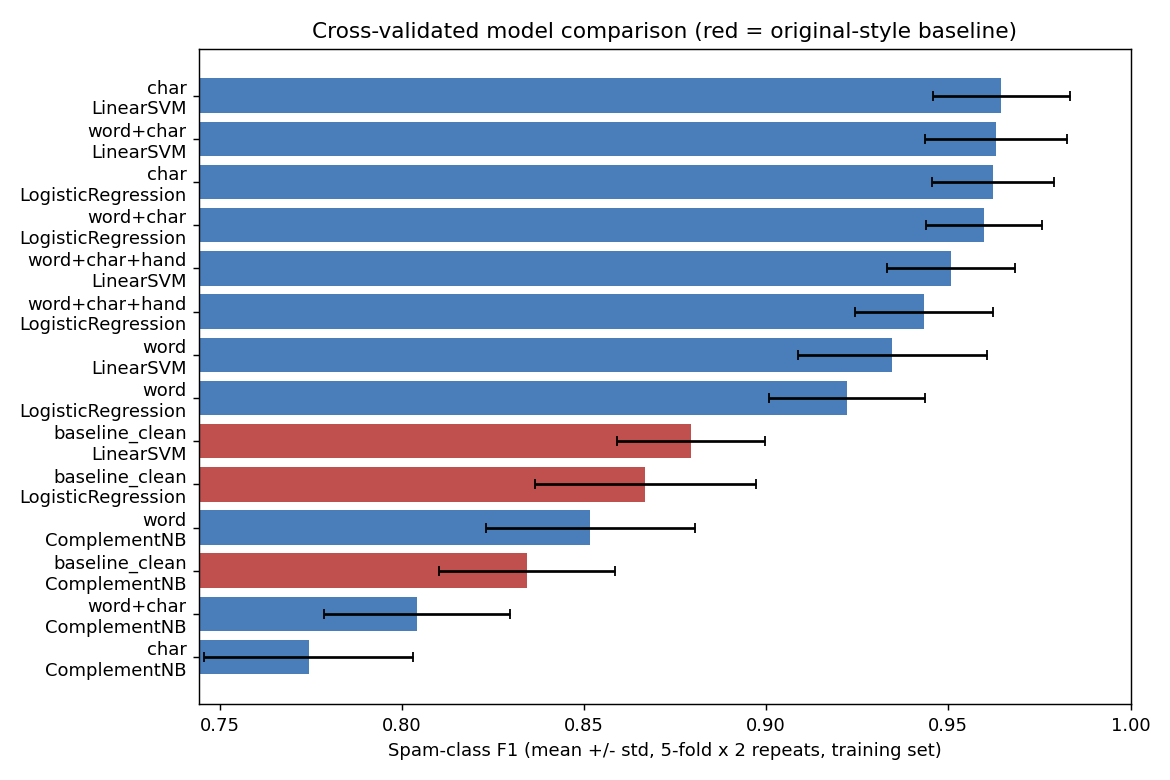

In [5]:
display(Image(str(OUT/"cv_comparison.png")))

**Reading the chart**

- The original-style baseline (cleaned text) is the weakest family for the same model type.
- Character n-grams on raw text give the biggest jump; word+char is statistically tied with char-only.
- Hand-crafted features (`word+char+hand`) did **not** help in cross-validation — a useful negative result: the
  n-grams already capture those signals. They stay in `src/features.py` for experimentation but are not used.
- Further sweeps (n-gram ranges, casing, `min_df`, logistic regression, feature unions, soft-voting ensemble, digit
  masking) all landed within ±0.003 F1 of the chosen model — below the fold-to-fold noise (~0.018) — or were worse.
- ComplementNB is fast but clearly weaker on character n-grams.

## 5. Final held-out test evaluation

In [6]:
m = json.loads((OUT/"test_metrics.json").read_text())
tbl = pd.DataFrame({
    "Original-style baseline": m["test_baseline_original_style"],
    "Improved @ threshold 0.5": m["test_improved_threshold_0.5"],
    "Improved @ tuned threshold": m["test_improved_tuned_threshold"],
}).T.round(3)
display(tbl)
print("Bootstrap 95% CI for the tuned model:")
for k,v in m["test_ci95"].items(): print(f"  {k:9}: [{v[0]:.3f}, {v[1]:.3f}]")
print(f"Threshold: {m['threshold']:.3f} | review band starts at {m['review_low']:.3f}")
print(f"Review rate: {m['review_rate']:.1%} | accuracy on auto-decided messages: {m['auto_decision_accuracy']:.4f}")
print(f"Test set: {m['n_test']} messages, {m['n_test_spam']} spam -> intervals are wide; don't over-read small differences.")

,precision,recall,f1
Original-style baseline,0.909,0.781,0.840
Improved @ threshold 0.5,0.984,0.938,0.960
Improved @ tuned threshold,0.976,0.961,0.969


Bootstrap 95% CI for the tuned model:
  precision: [0.945, 1.000]
  recall   : [0.926, 0.992]
  f1       : [0.945, 0.988]
Threshold: 0.217 | review band starts at 0.024
Review rate: 5.4% | accuracy on auto-decided messages: 0.9949
Test set: 1032 messages, 128 spam -> intervals are wide; don't over-read small differences.


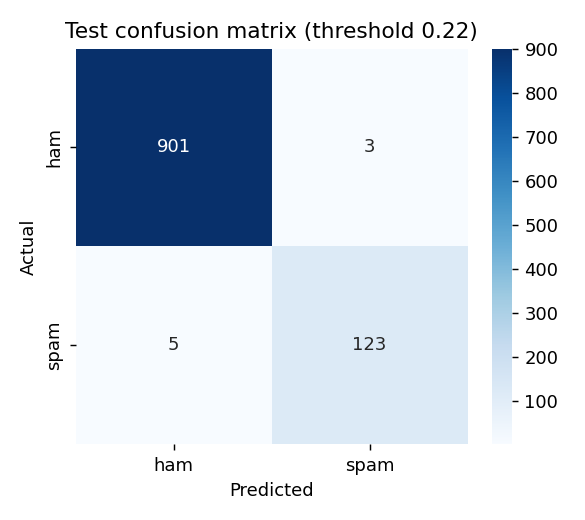

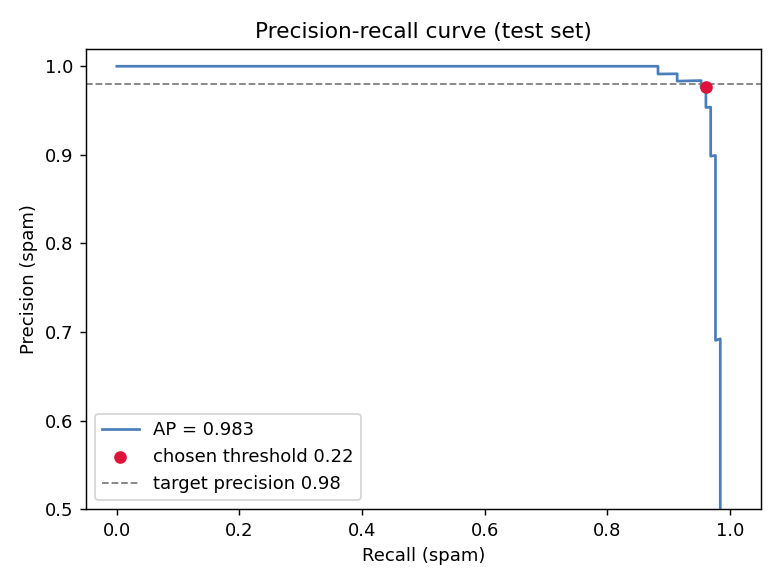

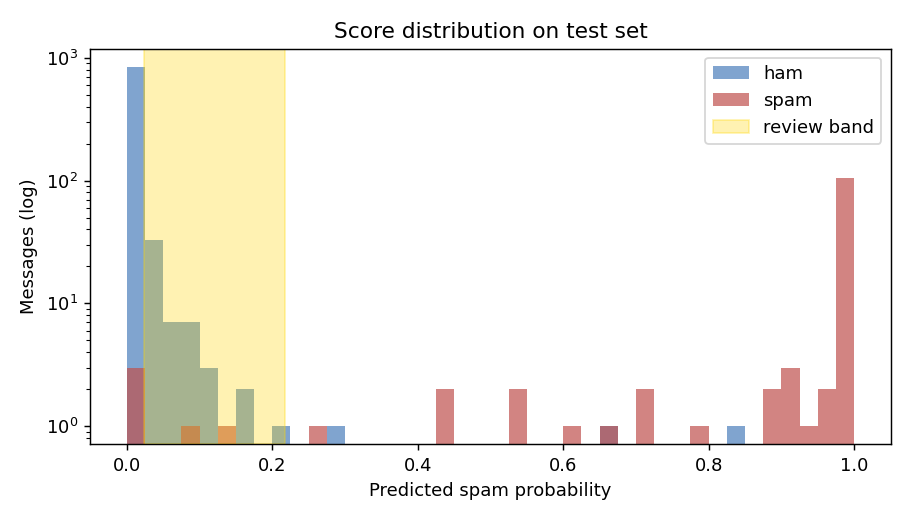

In [7]:
display(Image(str(OUT/"confusion_matrix.png"), width=380))
display(Image(str(OUT/"precision_recall_curve.png"), width=520))
display(Image(str(OUT/"score_distribution.png"), width=560))

### Sanity check: re-create the test predictions from the saved model

In [8]:
import joblib
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold

model = joblib.load(ROOT/"models"/"model.joblib"); cfg = json.loads((ROOT/"models"/"config.json").read_text())
# same grouped split train.py uses
_, te_i = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(df.message, df.label_num, df.group))
X_te, y_te = df.message.iloc[te_i], df.label_num.iloc[te_i]
pred = (model.predict_proba(X_te)[:,1] >= cfg["threshold"]).astype(int)
print(confusion_matrix(y_te, pred))
print(classification_report(y_te, pred, target_names=["ham","spam"], digits=3))

[[901   3]
 [  5 123]]
              precision    recall  f1-score   support

         ham      0.994     0.997     0.996       904
        spam      0.976     0.961     0.969       128

    accuracy                          0.992      1032
   macro avg      0.985     0.979     0.982      1032
weighted avg      0.992     0.992     0.992      1032



## 6. Error analysis

In [9]:
err = pd.read_csv(OUT/"error_analysis.csv")
print(err.outcome.value_counts().to_string())
err[err.outcome != "needs_review"]

outcome
needs_review      53
false_negative     5
false_positive     3


,message,true,spam_prob,outcome
0,"Do you ever notice that when you're driving, anyone going slower than you is an idiot and everyone driving faster th...",1,0.0002,false_negative
1,"Latest News! Police station toilet stolen, cops have nothing to go on!",1,0.0820,false_negative
2,"Oh my god! I've found your number again! I'm so glad, text me back xafter this msgs cst std ntwk chg £1.50",1,0.1307,false_negative
3,"Will u meet ur dream partner soon? Is ur career off 2 a flyng start? 2 find out free, txt HORO followed by ur star s...",1,0.0249,false_negative
4,"Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?",1,0.0017,false_negative
5,Check wid corect speling i.e. Sarcasm,0,0.2929,false_positive
6,"We have sent JD for Customer Service cum Accounts Executive to ur mail id, For details contact us",0,0.6679,false_positive
7,"Hi, Mobile no. <#> has added you in their contact list on www.fullonsms.com It s a great place to send free sms to p...",0,0.8436,false_positive


**What the mistakes show**

- *False negatives* are mostly chatty / quiz / premium-rate spam that looks like ordinary conversation — the spam nature
  lives in a hidden subscription, not in the wording.
- *False positives* include a **bank security notice** (legit, but phrased like phishing) and "send FREE SMS" invitations.
  These are truly ambiguous — exactly what the REVIEW band and human/rule checks are for.
- Sweeps of classical variants show no gain, so the remaining errors need new information (more data, sender/URL signals,
  or a pretrained language model), not more tuning.

In [10]:
err[err.outcome == "needs_review"].sort_values("spam_prob", ascending=False).head(10)

,message,true,spam_prob,outcome
42,K..u also dont msg or reply to his msg..,0,0.2122,needs_review
12,My tuition is at 330. Hm we go for the 1120 to 1205 one? Do you mind?,0,0.1702,needs_review
23,It's é only $140 ard...É rest all ard $180 at least...Which is é price 4 é 2 bedrm ($900),0,0.1529,needs_review
20,CHEERS FOR CALLIN BABE.SOZI CULDNT TALKBUT I WANNATELL U DETAILS LATER WENWECAN CHAT PROPERLY X,0,0.1229,needs_review
8,"Please protect yourself from e-threats. SIB never asks for sensitive information like Passwords,ATM/SMS PIN thru ema...",0,0.1110,needs_review
21,"Urgh, coach hot, smells of chip fat! Thanks again, especially for the duvet (not a predictive text word).",0,0.1063,needs_review
15,staff.science.nus.edu.sg/~phyhcmk/teaching/pc1323,0,0.0992,needs_review
49,Fffff. Can you text kadeem or are you too far gone,0,0.0958,needs_review
18,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Calle...,0,0.0923,needs_review
30,This is ur face test ( 1 2 3 4 5 6 7 8 9 <#> ) select any number i will tell ur face astrology.... am waiting. quick...,0,0.0923,needs_review


## 7. What the model learned (interpretability)

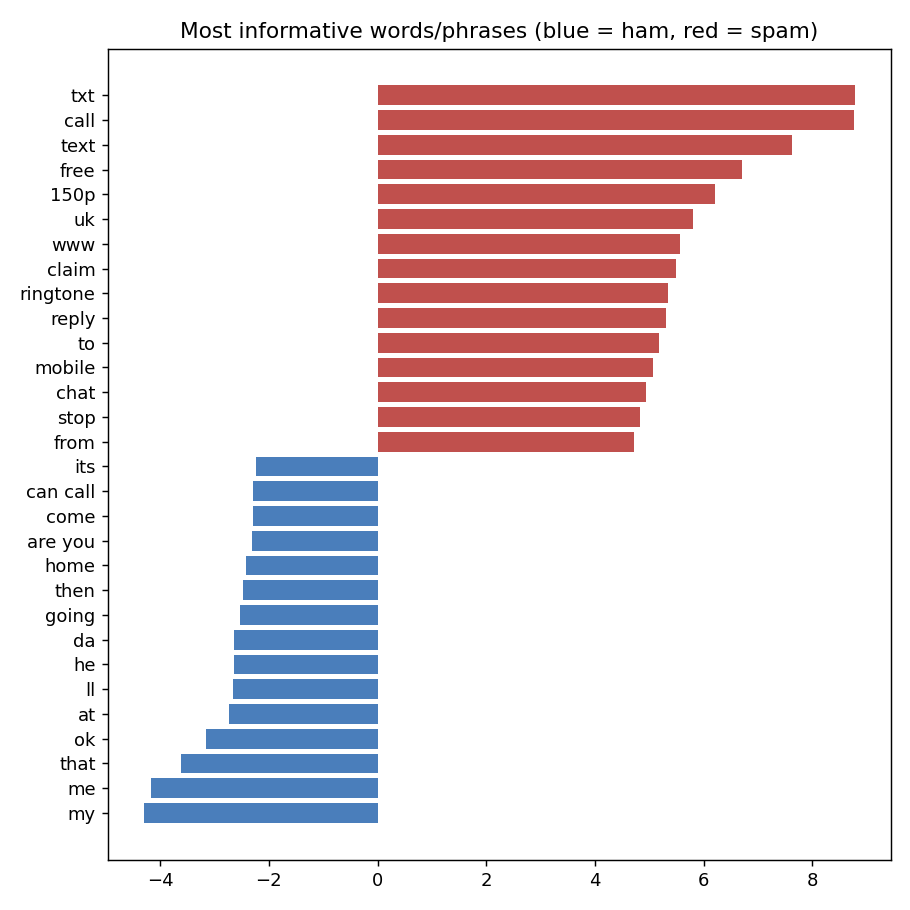

In [11]:
display(Image(str(OUT/"top_features.png"), width=560))

Sensible, human-readable cues: spam is driven by words like *txt, call, text, free, reply, claim, ringtone*, premium-rate price tokens such as *150p*, and web fragments (*www, uk*), while ham is dominated by conversational words (*my, me, ok, home, going*).

Earlier versions showed `gt` / `lt` as ham features — an artefact of `&lt;#&gt;` HTML leftovers in the raw data. They are **gone** now that text is HTML-unescaped, a small but real generalisation fix.

## 8. Robustness to obfuscated spam

Every spam message in the test set is rewritten with leetspeak / dotted / split words. Ham is left untouched.

In [12]:
r = m["obfuscation_robustness"]
pd.DataFrame({"Plain training": [r["clean_recall_plain"], r["obfuscated_recall_plain"]],
              "+ obfuscation augmentation": [r["clean_recall_augmented"], r["obfuscated_recall_augmented"]]},
             index=["Recall on clean spam", "Recall on obfuscated spam"]).round(3)

,Plain training,+ obfuscation augmentation
Recall on clean spam,0.969,0.961
Recall on obfuscated spam,0.938,0.984


## 9. Explaining a single prediction

Word *occlusion*: remove each word and measure the change in spam log-odds (positive = pushes towards spam).

In [13]:
from src.explain import explain

for msg in ["FREE entry! Text WIN to 80086 now to claim your prize", "fr33 msg: y0u w1n a prize, txt CLAIM to 81010"]:
    print(msg); print("   ", [(w, round(d, 2)) for w, d in explain(msg)])

FREE entry! Text WIN to 80086 now to claim your prize


    [('Text', 2.34), ('FREE', 2.32), ('80086', 1.55), ('claim', 0.87), ('prize', 0.76)]
fr33 msg: y0u w1n a prize, txt CLAIM to 81010
    [('txt', 1.13), ('81010', 0.71), ('prize,', 0.68), ('msg:', 0.4), ('CLAIM', -0.36)]


## 10. Try your own messages

In [14]:
from src.inference import classify

tests = [
 "Congratulations! You've won a $1000 Walmart gift card. Click here to claim now!",
 "Hey, are we still meeting for lunch tomorrow at 1pm?",
 "URGENT! Your account has been suspended. Verify your details immediately.",
 "fr33 msg: y0u w1n a prize, txt CLAIM to 81010",
 "Reminder: your electricity bill payment is due tomorrow, please pay to avoid late fee.",
 "Mom, call me back when you get a chance",
]
pd.DataFrame(classify(tests)).round(3)

,message,spam_probability,decision
0,Congratulations! You've won a $1000 Walmart gift card. Click here to claim now!,0.760,SPAM
1,"Hey, are we still meeting for lunch tomorrow at 1pm?",0.002,HAM
2,URGENT! Your account has been suspended. Verify your details immediately.,0.266,SPAM
3,"fr33 msg: y0u w1n a prize, txt CLAIM to 81010",0.951,SPAM
4,"Reminder: your electricity bill payment is due tomorrow, please pay to avoid late fee.",0.018,HAM
5,"Mom, call me back when you get a chance",0.011,HAM


## 11. Conclusions

- **Result**: on the held-out grouped test set the improved pipeline reaches spam **F1 ≈ 0.97** (precision ≈ 0.98, recall ≈ 0.96) versus
  **≈ 0.84** for the original-style baseline on the same split. Cross-validated F1 tells the same story (≈ 0.965 vs ≈ 0.88).
- **Why**: raw text (digits, symbols, case) + character n-grams; a class-weighted linear SVM; augmentation against obfuscation;
  and a threshold tuned for the business goal instead of the default.
- **Robustness**: recall on obfuscated spam rises from ≈ 0.94 to ≈ 0.98 with no loss on clean spam.
- **Honesty about uncertainty**: only ~128 spam messages are in the test set, so the 95% CIs are wide (F1 roughly 0.94–0.99).
  Differences of ~0.01 between models are within noise.
- **Note on comparability**: scores differ from earlier versions because the split is grouped, text is unescaped and the selection
  procedure is honest; do not compare the old 0.9375 directly with these numbers.
- **Limitations**: English SMS only; dataset is from ~2004–2012 and its style differs from modern phishing/WhatsApp spam.
- **Next steps**: pretrained-embedding / DistilBERT model under the same protocol; newer multilingual data; sender/URL checks
  for the REVIEW band; log reviewer decisions and retrain.